# Predicting Forest Fire Burned Area with Regression
*CM 764 Statistical Learning: Advanced Regression (cross-listed as STAT 844), University of Waterloo, Spring 2025*

## 1. Setup

In [1]:
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import LeaveOneOut, train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer

## 2. Data
### 2.1 Load the Dataset and Encode Month and Day

In [2]:
# fetch dataset 
forest_fires = fetch_ucirepo(id=162) 
  
# data (as pandas dataframes) 
X = forest_fires.data.features 
y = forest_fires.data.targets 
  
# month and day contains strings, we first turn them into integers
month_map = {
    'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4,
    'may': 5, 'jun': 6, 'jul': 7, 'aug': 8,
    'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
}
day_map = {
    'mon': 1, 'tue': 2, 'wed': 3,
    'thu': 4, 'fri': 5, 'sat': 6, 'sun': 7
}
X["month_int"] = X["month"].map(month_map)
X["day_int"] = X["day"].map(day_map)

# apply cyclical encoding to month_int and day_int
X['month_sin'] = np.sin(2 * np.pi * X['month_int'] / 12)
X['month_cos'] = np.cos(2 * np.pi * X['month_int'] / 12)
X['day_sin'] = np.sin(2 * np.pi * X['day_int'] / 7)
X['day_cos'] = np.cos(2 * np.pi * X['day_int'] / 7)
X.drop(columns=["month", "day", "month_int", "day_int"], inplace=True)

### 2.2 Distribution of Burned Area

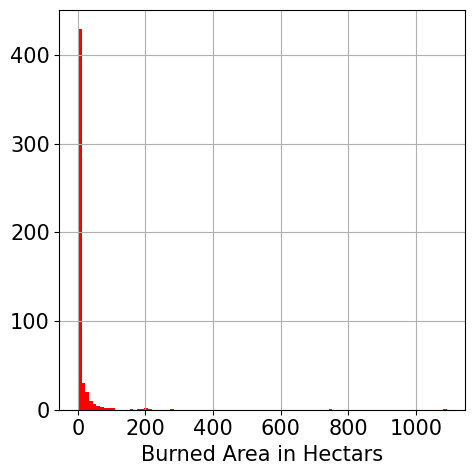

In [3]:
plt.rcParams.update({'font.size': 15})
plt.figure(figsize=(5, 5))
plt.hist(y, bins=100, color='r')
plt.xlabel("Burned Area in Hectars")
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/histY.pdf", bbox_inches='tight')
plt.savefig("figures/histY.png", dpi=200, bbox_inches='tight')
plt.show()

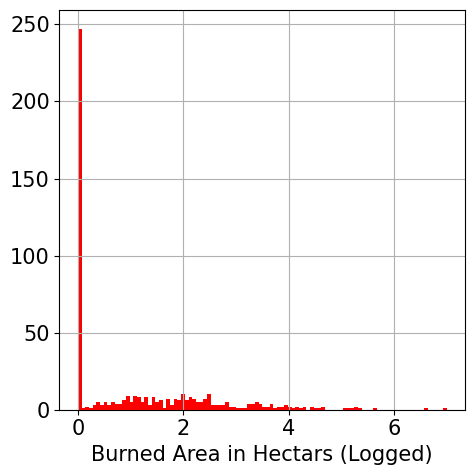

In [4]:
plt.figure(figsize=(5, 5))
plt.hist(np.log(y+1), bins=100, color='r')
plt.xlabel("Burned Area in Hectars (Logged)")
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/histYLog.pdf", bbox_inches='tight')
plt.savefig("figures/histYLog.png", dpi=200, bbox_inches='tight')
plt.show()

### 2.3 Log-Transform the Target

In [5]:
y = np.log(y+1)

### 2.4 Train/Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=69)

## 3. Leave-One-Out Cross-Validation Helper

In [7]:
def printScores(X, y, model, scorer):
    loo = LeaveOneOut()
    scores = cross_val_score(model, X, y, cv=loo, scoring=scorer)
    mean_loo_mse = -scores.mean()
    print(f"{model.__class__.__name__} LOO-CV MSE: {mean_loo_mse}")
    return mean_loo_mse

## 4. Models
### 4.1 Linear Regression

In [8]:
modelLinReg = LinearRegression()
scorer = make_scorer(mean_squared_error,greater_is_better=False)
mse = printScores(X_train, y_train, modelLinReg, scorer)

LinearRegression LOO-CV MSE: 2.106583569973412


#### Predicted vs. True Area

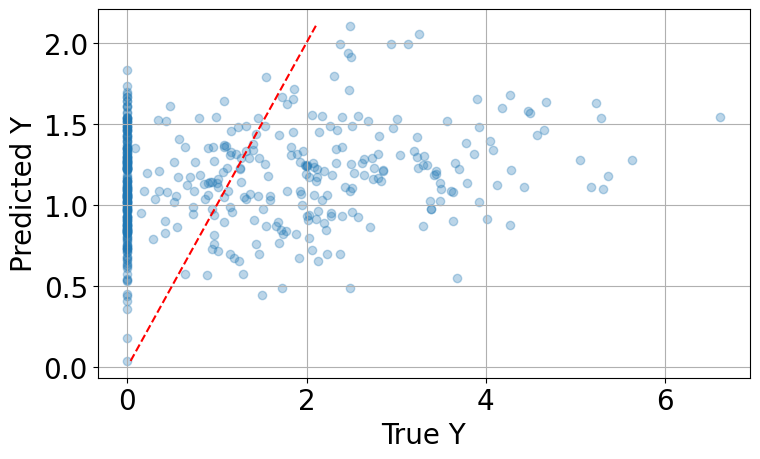

In [9]:
modelLinReg.fit(X_train, y_train)
y_pred = modelLinReg.predict(X_train)
plt.rcParams.update({'font.size': 20})
plt.figure(figsize=(8, 5))
plt.scatter(y_train, y_pred, alpha=0.3)
plt.plot([y_pred.min(), y_pred.max()], [y_pred.min(), y_pred.max()], 'r--')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/LinReg.pdf", bbox_inches='tight')
plt.savefig("figures/LinReg.png", dpi=200, bbox_inches='tight')
plt.show()

### 4.2 K-Nearest Neighbours
#### Tuning the Number of Neighbours

In [10]:
neighbours = range(2, 50, 2)
mse = []
modelKNN = []
for nei in neighbours:
    model = KNeighborsRegressor(n_neighbors=nei)
    modelKNN.append(model)
    scorer = make_scorer(mean_squared_error,greater_is_better=False)
    mse.append(printScores(X_train, y_train, model, scorer))

mse = np.array(mse)
print(f"Best k is {neighbours[np.argmin(mse)]} with LOO-CV MSE {min(mse)}")

KNeighborsRegressor LOO-CV MSE: 2.8950752923274585
KNeighborsRegressor LOO-CV MSE: 2.439121443741914
KNeighborsRegressor LOO-CV MSE: 2.218193203351111
KNeighborsRegressor LOO-CV MSE: 2.1981378464467225
KNeighborsRegressor LOO-CV MSE: 2.1817731551284067
KNeighborsRegressor LOO-CV MSE: 2.117146115650755
KNeighborsRegressor LOO-CV MSE: 2.088186633092244
KNeighborsRegressor LOO-CV MSE: 2.0608317817243633
KNeighborsRegressor LOO-CV MSE: 2.048945798303161
KNeighborsRegressor LOO-CV MSE: 2.0393735578707224
KNeighborsRegressor LOO-CV MSE: 2.0258611183012367
KNeighborsRegressor LOO-CV MSE: 1.9983424786271518
KNeighborsRegressor LOO-CV MSE: 1.9951173688400674
KNeighborsRegressor LOO-CV MSE: 1.9860704436600107
KNeighborsRegressor LOO-CV MSE: 1.971351397752139
KNeighborsRegressor LOO-CV MSE: 1.979296513009377
KNeighborsRegressor LOO-CV MSE: 1.9803339138211633
KNeighborsRegressor LOO-CV MSE: 1.987579564811814
KNeighborsRegressor LOO-CV MSE: 1.997708940018067
KNeighborsRegressor LOO-CV MSE: 1.998808

#### LOO-CV Error vs. k

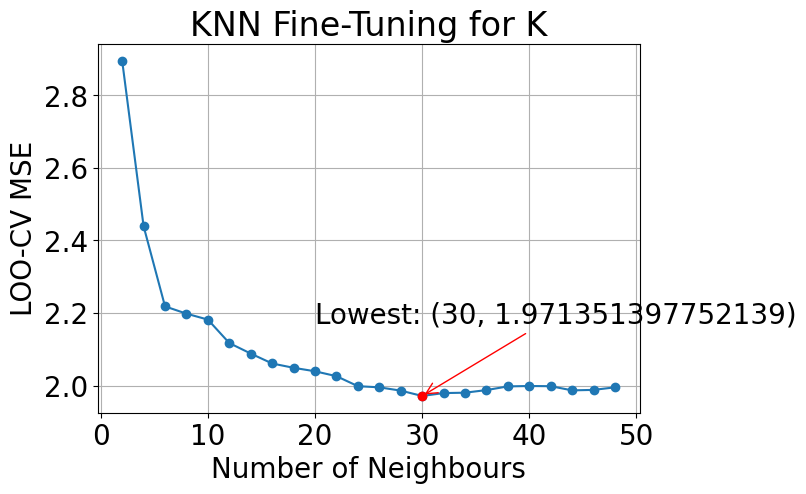

In [11]:
minInd = np.argmin(mse)
min_x = neighbours[minInd]
min_y = mse[minInd]
plt.figure(figsize=(8, 5))
plt.plot(neighbours, mse, marker='o', linestyle='-')
plt.plot(min_x, min_y, 'ro')
plt.annotate(f'Lowest: ({min_x}, {min_y})',
             xy=(min_x, min_y),
             xytext=(min_x - 10, min_y + 0.2),
             arrowprops=dict(arrowstyle='->', color='red'))
plt.xlabel('Number of Neighbours')
plt.ylabel('LOO-CV MSE')
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/KNNNeighbours.pdf", bbox_inches='tight')
plt.title('KNN Fine-Tuning for K')
plt.show()

#### Predicted vs. True Area

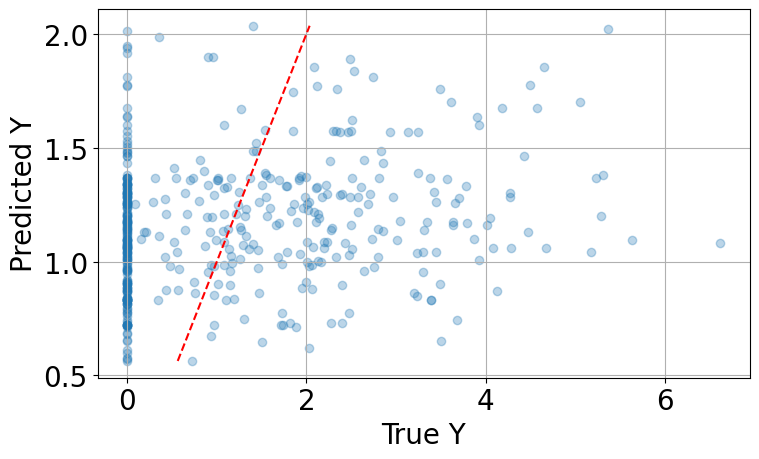

In [12]:
modelKNN[14].fit(X_train, y_train)
y_pred = modelKNN[14].predict(X_train)
plt.figure(figsize=(8, 5))
plt.scatter(y_train, y_pred, alpha=0.3)
plt.plot([y_pred.min(), y_pred.max()], [y_pred.min(), y_pred.max()], 'r--')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/KNN.pdf", bbox_inches='tight')
plt.savefig("figures/KNN.png", dpi=200, bbox_inches='tight')
plt.show()

### 4.3 Ridge Regression
#### Tuning the Penalty α

In [13]:
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

alphas = np.logspace(-1, 15, 100)
modelRidge = make_pipeline(StandardScaler(), 
                           RidgeCV(alphas=alphas, scoring='neg_mean_squared_error', 
                                   cv=None, store_cv_results=True))
modelRidge.fit(X_train, y_train)
print("Best alpha:", modelRidge[1].alpha_)

make_scorer(mean_squared_error,greater_is_better=False)
mse = printScores(X_train, y_train, modelRidge, scorer)

Best alpha: 756.463327554629
Pipeline LOO-CV MSE: 1.9943441173152383


#### Coefficients

In [14]:
print("Coefficients:", modelRidge[1].coef_)

Coefficients: [ 0.03369916  0.01613823  0.0187426   0.0314321   0.02462764 -0.01981433
  0.01281537 -0.01490599  0.0468366   0.00981961 -0.02664402  0.05283726
  0.01766815  0.0192881 ]


#### Cross-Validation Error vs. α

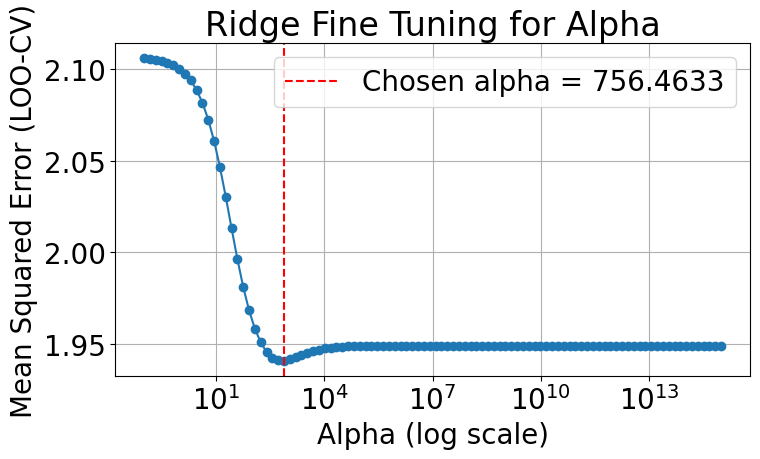

Lowest LOO-CV MSE: 1.9406096025305426


In [15]:
loo_preds = modelRidge[1].cv_results_.squeeze()
mean_mse = np.mean((loo_preds - y_train.to_numpy()) ** 2, axis=0)
plt.figure(figsize=(8, 5))
plt.plot(alphas, mean_mse, marker='o')
plt.xscale("log")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Mean Squared Error (LOO-CV)")
plt.title("Ridge Fine Tuning for Alpha")
plt.axvline(modelRidge[1].alpha_, color='red', linestyle='--', label=f"Chosen alpha = {modelRidge[1].alpha_:.4f}")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/RidgeCVAlpha.pdf", bbox_inches='tight')
plt.show()
print("Lowest LOO-CV MSE:", mean_mse.min())

#### Predicted vs. True Area

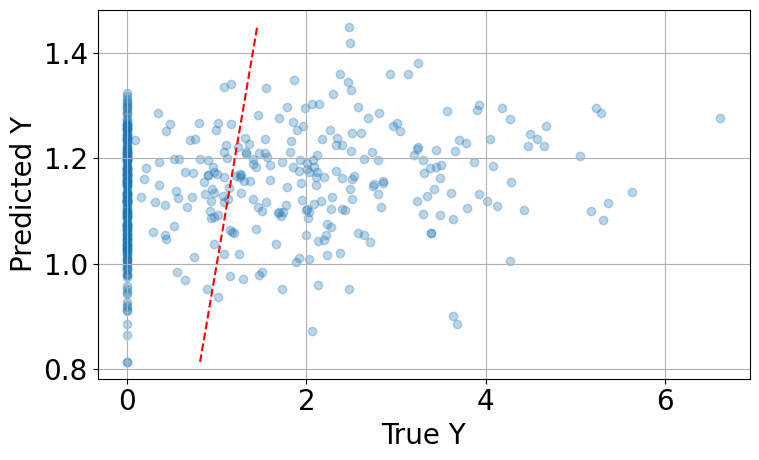

In [16]:
y_pred = modelRidge.predict(X_train)
plt.figure(figsize=(8, 5))
plt.scatter(y_train, y_pred, alpha=0.3)
plt.plot([y_pred.min(), y_pred.max()], [y_pred.min(), y_pred.max()], 'r--')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/RidgeReg.pdf", bbox_inches='tight')
plt.savefig("figures/RidgeReg.png", dpi=200, bbox_inches='tight')
plt.show()

### 4.4 Polynomial Regression
#### Tuning the Degree

In [17]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
degrees = range(2,5)
mse = []
modelPoly = []
for degree in degrees:
    print(f"Degree {degree}:")
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    modelPoly.append(model)
    scorer = make_scorer(mean_squared_error,greater_is_better=False)
    mse.append(printScores(X_train, y_train, model, scorer))
    
mse = np.array(mse)
print(f"Best degree is {np.argmin(mse)+2} with LOO-CV MSE {min(mse)}") 

Degree 2:
Pipeline LOO-CV MSE: 3.751284581909279
Degree 3:
Pipeline LOO-CV MSE: 5822.168482035252
Degree 4:
Pipeline LOO-CV MSE: 3960.042176996346
Best degree is 2 with LOO-CV MSE 3.751284581909279


#### Predicted vs. True Area

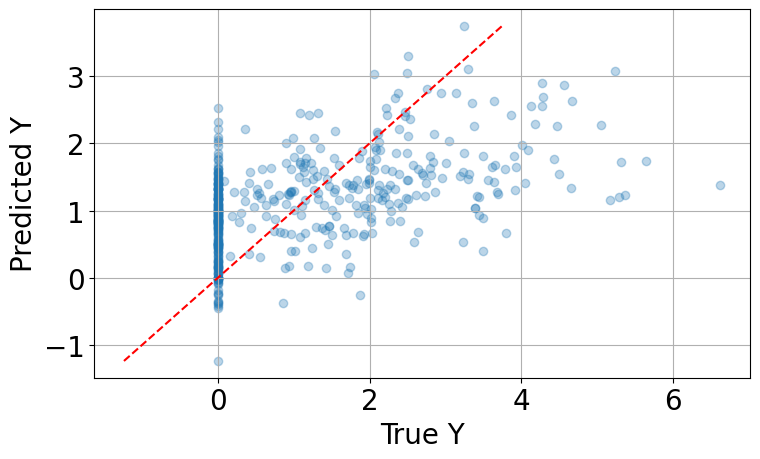

In [18]:
modelPoly[0].fit(X_train, y_train)
y_pred = modelPoly[0].predict(X_train)
plt.figure(figsize=(8, 5))
plt.scatter(y_train, y_pred, alpha=0.3)
plt.plot([y_pred.min(), y_pred.max()], [y_pred.min(), y_pred.max()], 'r--')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/PolyReg.pdf", bbox_inches='tight')
plt.savefig("figures/PolyReg.png", dpi=200, bbox_inches='tight')
plt.show()

### 4.5 Cubic Spline Regression
#### Tuning the Number of Knots

In [19]:
import warnings
from sklearn.exceptions import FitFailedWarning
warnings.filterwarnings("ignore", category=FitFailedWarning)
from sklearn.preprocessing import SplineTransformer
knots = list(range(2,10)) + list(range(10, 51, 10))
mse = []
modelsSplineLin = []
for kn in knots:
    print(f"Knots: {kn}")
    spline_transformer = SplineTransformer(n_knots=kn, degree=3, knots="quantile")
    model = make_pipeline(spline_transformer, LinearRegression())
    modelsSplineLin.append(model)
    scorer = make_scorer(mean_squared_error,greater_is_better=False)
    mse.append(printScores(X_train, y_train, model, scorer))

mse = np.array(mse)
print(f"Best Knot count is {knots[np.nanargmin(mse)]} with LOO-CV MSE {np.nanmin(mse)}")

Knots: 2
Pipeline LOO-CV MSE: 2.06399307523384
Knots: 3
Pipeline LOO-CV MSE: 2.1134617919185463
Knots: 4
Pipeline LOO-CV MSE: 2.255833106820854
Knots: 5
Pipeline LOO-CV MSE: 2.9058587378287193
Knots: 6
Pipeline LOO-CV MSE: 4.046945242472388
Knots: 7
Pipeline LOO-CV MSE: 3.4915985401771366
Knots: 8
Pipeline LOO-CV MSE: nan
Knots: 9
Pipeline LOO-CV MSE: 4.036919777211209
Knots: 10
Pipeline LOO-CV MSE: 3.293144059355675
Knots: 20
Pipeline LOO-CV MSE: 3.510100267215703
Knots: 30
Pipeline LOO-CV MSE: 20.032173130495107
Knots: 40
Pipeline LOO-CV MSE: 1224.118941719424
Knots: 50
Pipeline LOO-CV MSE: 921240848903.9856
Best Knot count is 2 with LOO-CV MSE 2.06399307523384


#### LOO-CV Error vs. Number of Knots

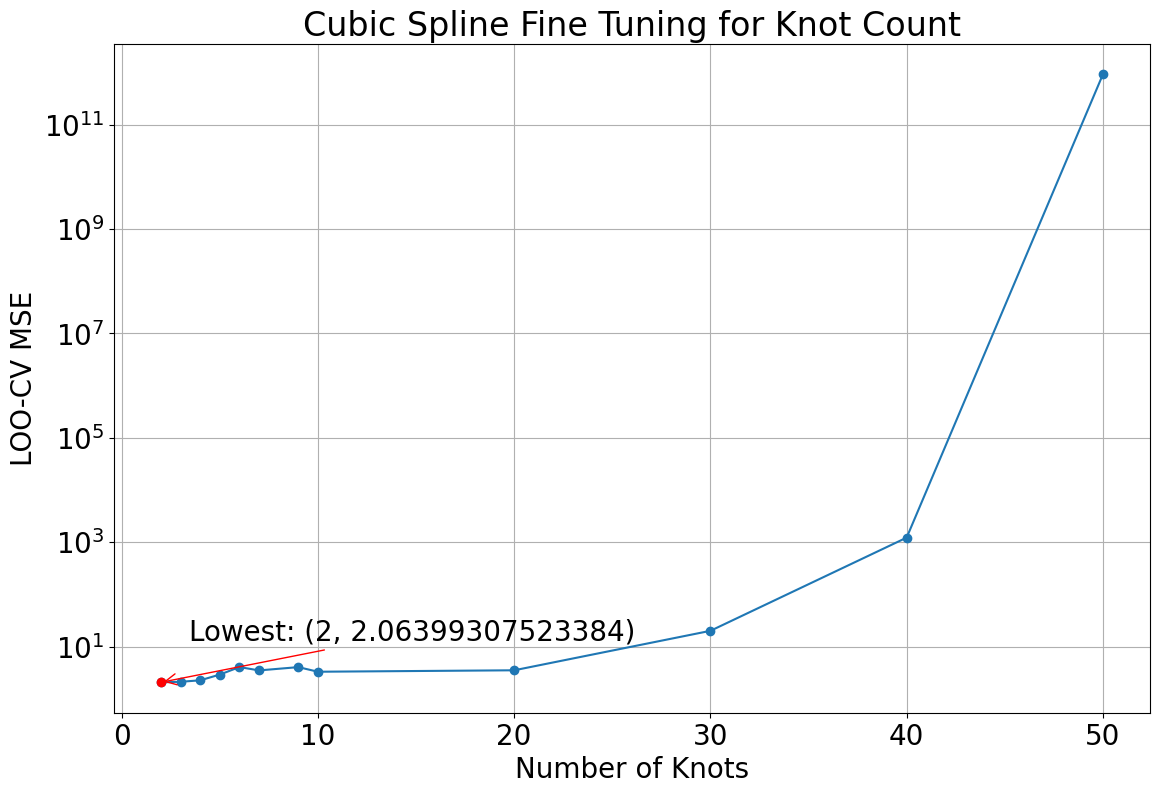

In [20]:
knots = np.array(knots)
nanInd = np.isnan(mse)
mse = mse[~nanInd]
knots = knots[~nanInd]

minInd = np.argmin(mse)
min_x = knots[minInd]
min_y = mse[minInd]
plt.figure(figsize=(12, 8))
plt.plot(knots, mse, marker='o', linestyle='-')
plt.plot(min_x, min_y, 'ro')
plt.yscale('log')
plt.annotate(f'Lowest: ({min_x}, {min_y})',
             xy=(min_x, min_y),
                xytext=(20, 30), textcoords='offset points',
             arrowprops=dict(arrowstyle='->', color='red'))
plt.xlabel('Number of Knots')
plt.ylabel('LOO-CV MSE')
plt.grid(True)
plt.tight_layout()
plt.title('Cubic Spline Fine Tuning for Knot Count')
plt.savefig("figures/CubicSplineKnots.pdf", bbox_inches='tight')
plt.show()

#### Predicted vs. True Area

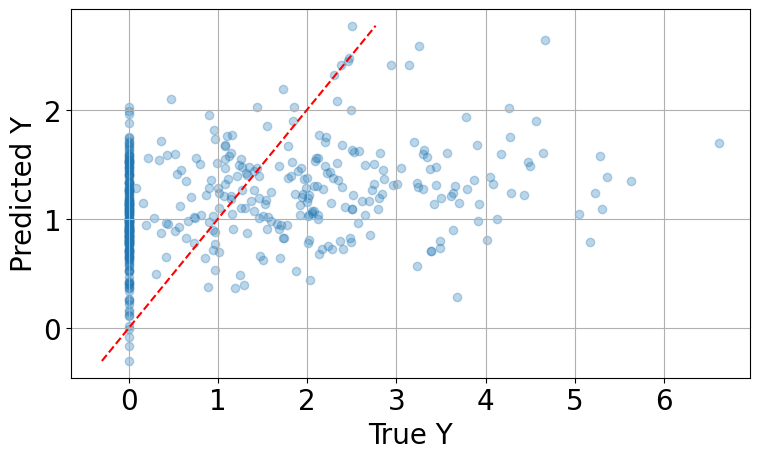

In [21]:
modelsSplineLin[0].fit(X_train, y_train)
y_pred = modelsSplineLin[0].predict(X_train)
plt.figure(figsize=(8, 5))
plt.scatter(y_train, y_pred, alpha=0.3)
plt.plot([y_pred.min(), y_pred.max()], [y_pred.min(), y_pred.max()], 'r--')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/CubicSpline.pdf", bbox_inches='tight')
plt.savefig("figures/CubicSpline.png", dpi=200, bbox_inches='tight')
plt.show()

### 4.6 Cubic Spline with a Ridge Penalty

In [22]:
from sklearn.preprocessing import SplineTransformer
knots = [2, 3, 4]
alphas = np.logspace(-1, 15, 100)

mse = []
modelsSplineRidge = []
for kn in knots:
    print(f"Knots: {kn}")
    spline_transformer = SplineTransformer(n_knots=kn, degree=3)
    ridge = RidgeCV(alphas=alphas, scoring='neg_mean_squared_error')
    model = make_pipeline(spline_transformer, ridge)
    modelsSplineRidge.append(model)
    scorer = make_scorer(mean_squared_error,greater_is_better=False)
    mse.append(printScores(X_train, y_train, model, scorer))

mse = np.array(mse)
best = np.argmin(mse)
print(f"Best knot count is {knots[best]} with LOO-CV MSE {mse[best]}")

Knots: 2
Pipeline LOO-CV MSE: 1.9581114835081812
Knots: 3
Pipeline LOO-CV MSE: 1.990593649123572
Knots: 4
Pipeline LOO-CV MSE: 1.9687550637761837
Best knot count is 2 with LOO-CV MSE 1.9581114835081812


#### Predicted vs. True Area

Chosen alpha: 12.61856883066021


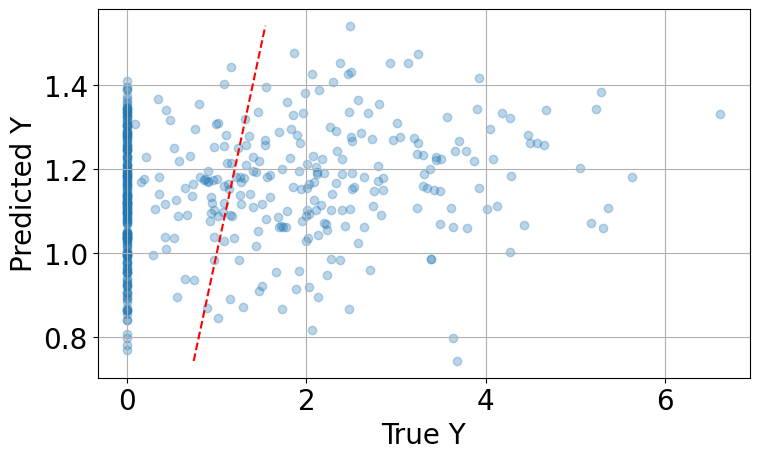

In [23]:
bestSplineRidge = modelsSplineRidge[best]
bestSplineRidge.fit(X_train, y_train)
print("Chosen alpha:", bestSplineRidge[1].alpha_)
y_pred = bestSplineRidge.predict(X_train)
plt.figure(figsize=(8, 5))
plt.scatter(y_train, y_pred, alpha=0.3)
plt.plot([y_pred.min(), y_pred.max()], [y_pred.min(), y_pred.max()], 'r--')
plt.xlabel('True Y')
plt.ylabel('Predicted Y')
plt.grid(True)
plt.tight_layout()
plt.savefig("figures/CubicSplineRidge.pdf", bbox_inches='tight')
plt.show()